# Customer Segmentation Using Clustering Models Lab

## Introduction

Customer segmentation is a critical process in marketing and business strategy, enabling companies to group customers based on shared characteristics and behaviors. By understanding these groups, businesses can personalize marketing campaigns, optimize product recommendations, improve customer retention, and enhance overall customer experience. Instead of treating all customers the same, segmentation allows businesses to target different groups with tailored offers, promotions, and engagement strategies, leading to higher customer satisfaction and increased revenue.

In this lab, you will **perform customer segmentation using k-means clustering and Gaussian Mixture Models (GMMs) on the Online Retail dataset**, which contains transactional data from an e-commerce retailer. This dataset includes purchase dates, transaction amounts, and unique customer identifiers, providing a solid foundation for analyzing customer behavior.

Your goal is to cluster customers based on their purchasing patterns, specifically using the Recency, Frequency, and Monetary (RFM) model:
- **Recency (R):** How recently a customer made a purchase.
- **Frequency (F):** How often a customer makes purchases.
- **Monetary Value (M):** How much a customer spends.

By clustering customers based on these factors, you will uncover distinct groups, including loyal customers, occasional buyers, high-value shoppers, and inactive customers. You will first determine the optimal number of clusters using the elbow method (WCSS for k-means) and Bayesian Information Criterion (BIC for GMM). Then, you will apply both clustering techniques and evaluate their effectiveness using silhouette scores. Finally, you will visualize the clustering results using Principal Component Analysis (PCA) to gain further insights into customer segmentation.

Through this lab, you will gain hands-on experience in data-driven customer segmentation, a technique widely used in industries such as e-commerce, banking, telecommunications, and retail.

### Step 0: Load and Prepare the Dataset

- Import any necessary libraries, including `KMeans` and `GaussianMixture` for clustering.
- Load the Online Retail dataset from the CSV file.
- Drop missing `CustomerID` values, as we need customer-level segmentation.
- Ensure proper data types:
    - Convert `CustomerID` to integer format.
    - Convert `InvoiceDate` to datetime format.

In [1]:
# CodeGrade step0

# Import any useful libraries:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

In [2]:
# CodeGrade step0

# Load the dataset:
df = pd.read_csv("OnlineRetail.csv", encoding = "latin1")

# Drop rows with missing `CustomerID`s (we can only segment customers we can
# actually identify):
df = df.dropna(subset = ["CustomerID"])

# Convert `CustomerID` to integer format:
df["CustomerID"] = df["CustomerID"].astype(int)

# Convert `InvoiceDate` to datetime format:
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])

### Step 1: Compute RFM Features and Normalize Data

Extract Recency, Frequency, and Monetary (RFM) features and standardize them.

- Define a reference date as the latest transaction in the dataset.
- Compute the RFM metrics:
    - **Recency:** Days since the last purchase.
    - **Frequency:** Number of unique transactions.
    - **Monetary:** Total amount spent.
- Rename the columns for clarity: `Recency`, `Frequency`, `Monetary`.
- Remove outliers by ensuring `Frequency` and `Monetary` values are greater than zero.
- Use `StandardScaler()` to standardize the RFM features.
- Ensure that the shape of the scaled dataset remains the same as the original data.

In [3]:
# CodeGrade step1

# Define a reference date as the latest transaction in the dataset:
reference_date = df["InvoiceDate"].max()

# Compute Recency, Frequency, and Monetary (RFM) metrics:
rfm = df.groupby("CustomerID").agg({
    "InvoiceDate": lambda x: (reference_date - x.max()).days,  # Recency
    "InvoiceNo": "nunique",  # Frequency (unique transactions)
    "UnitPrice": "sum"  # Monetary value (total spent)
    })

# Rename columns for clarity:
rfm.columns = ["Recency", "Frequency", "Monetary"]

# Remove customers with nonpositive `Frequency` or `Monetary` values:
rfm = rfm[(rfm["Frequency"] > 0) & (rfm["Monetary"] > 0)]

# Standardize the features:
scaler = StandardScaler()
rfm_scaled = scaler.fit_transform(rfm)

# Check that the shape of `rfm_scaled` is the same as the shape of `rfm`:
print(f"Shape of original RFM data: {rfm.shape}")
print(f"Shape of standardized RFM data: {rfm_scaled.shape}")

Shape of original RFM data: (4371, 3)
Shape of standardized RFM data: (4371, 3)


### Step 2: Determine the Optimal Number of Clusters for K-Means (Elbow Method)

Use within-cluster sum of squares (WCSS) to determine the best k for k-means.

- Initialize an empty list called `wcss`.
- Loop over values of k from 1 to 9:
    - Train a `KMeans` model with the current k, `random_state = 42` and `n_init = 10`.
    - Fit the model to `rfm_scaled` and store the inertia (WCSS) value in `wcss`.
- Compute and return the mean WCSS value rounded to two decimal places.

In [4]:
# CodeGrade step2

# Initialize an empty list to store the WCSS values:
wcss = []

# Loop over values of k from 1-9:
for k in range(1, 10):
    kmeans = KMeans(n_clusters = k, random_state = 42, n_init = 10)
    kmeans.fit(rfm_scaled)
    wcss.append(kmeans.inertia_)

# Calculate and return the mean of WCSS:
print(f"Mean WCSS: {np.mean(wcss):.2f}")

Mean WCSS: 4540.13


Plot the graph for the elbow method:
- X-axis: Number of clusters (k).
- Y-axis: WCSS values.
- Use `marker = "o"` and `linestyle = "-"`.

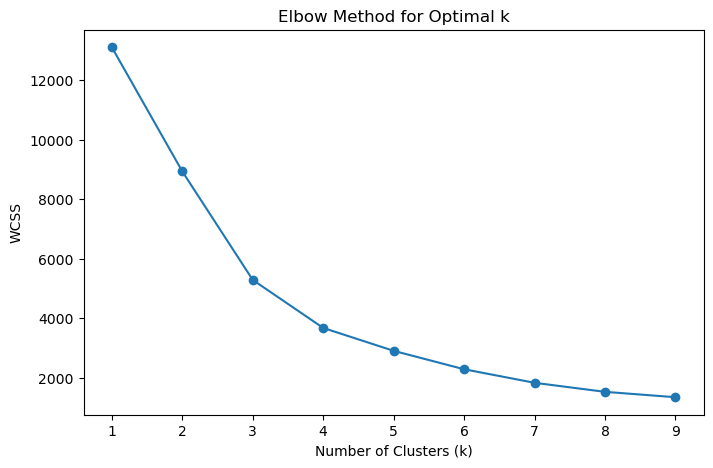

In [5]:
# Plot the elbow curve:
plt.figure(figsize = (8, 5))
plt.plot(range(1, 10), wcss, marker = "o", linestyle = "-")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("WCSS")
plt.title("Elbow Method for Optimal k")
plt.show()

### Step 3: Determine the Optimal Number of Components for GMM (AIC & BIC Method)

Use AIC & BIC to determine the best k for GMM.

- Initialize two empty lists: `bic_scores` and `aic_scores`.
- Loop over values of k from 1 to 9:
    - Train a `GaussianMixture` model with the current k components, `random_state = 42`, and `n_init = 10`.
    - Fit the model to `rfm_scaled` and store the BIC and AIC scores.
- Compute and return the difference between the sum of BIC scores and the sum of AIC scores, rounded to zero decimal places.

In [6]:
# CodeGrade step3

# Initialize two empty lists to store the BIC and AIC scores:
bic_scores = []
aic_scores = []
k_values = range(1, 10)

# Loop over values of k from 1-9:
for k in k_values:
    gmm = GaussianMixture(n_components = k, random_state = 42, n_init = 10)
    gmm.fit(rfm_scaled)
    bic_scores.append(gmm.bic(rfm_scaled))
    aic_scores.append(gmm.aic(rfm_scaled))

# Calculate and return the difference in sums:
print(f"Difference in sum of BIC scores and AIC scores: {sum(bic_scores) - 
      sum(aic_scores):.0f}")

Difference in sum of BIC scores and AIC scores: 2815


Plot the BIC score to visualize the optimal k:
- X-axis: Number of components (k).
- Y-axis: BIC score.
- Use `marker = "o"` and `linestyle = "-"`.

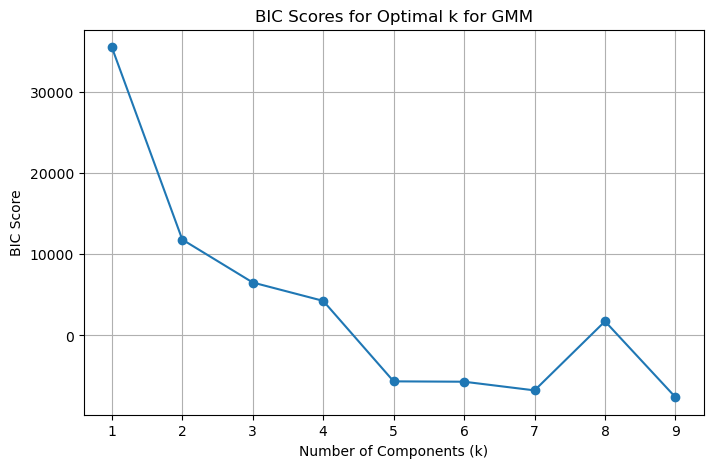

In [7]:
# Plot BIC scores to find the optimal K:
plt.figure(figsize = (8, 5))
plt.plot(k_values, bic_scores, marker = "o", linestyle = "-")
plt.xlabel("Number of Components (k)")
plt.ylabel("BIC Score")
plt.title("BIC Scores for Optimal k for GMM")
plt.grid(True)
plt.show()

You can also plot AIC, or both.

### Step 4: Apply K-Means and GMM Clustering

Apply both k-means and GMM clustering using the optimal number of clusters.

- Set `optimal_k = 4` (determined from the previous two steps).
- Train a `KMeans` model with `optimal_k`, `random_state = 42`, and `n_init = 10`.
- Assign cluster labels to a new column called `rfm["KMeans_Cluster"]`.
- Train a `GaussianMixture` model with `optimal_k`, `random_state = 42`, and `n_init = 10`.
- Assign cluster labels to a new column called `rfm["GMM_Cluster"]`.
- Compute the maximum cluster probability for each sample and store it in `rfm["GMM_Probability"]`.
- Compute the silhouette scores for both clustering methods.
- Return both silhouette scores rounded to four decimal places.

In [8]:
# CodeGrade step4

# Set the optimal k specified in Step 4 (even though the BIC graph for GMM
# probably indicates using k = 5):
optimal_k = 4

# Apply k-means clustering:
kmeans = KMeans(n_clusters = optimal_k, random_state = 42, n_init = 10)
rfm["KMeans_Cluster"] = kmeans.fit_predict(rfm_scaled)

# Apply GMM clustering:
gmm = GaussianMixture(n_components = optimal_k, random_state = 42, n_init = 10)
gmm.fit(rfm_scaled)

# Predict cluster labels:
rfm["GMM_Cluster"] = gmm.predict(rfm_scaled)

# Predict the maximum cluster probability for each sample:
rfm["GMM_Probability"] = gmm.predict_proba(rfm_scaled).max(axis = 1)

# Validate clustering quality using the silhouette score for each model:
silhouette_kmeans = silhouette_score(rfm_scaled, rfm["KMeans_Cluster"])
silhouette_gmm = silhouette_score(rfm_scaled, rfm["GMM_Cluster"])

# Return both silhouette scores rounded to four decimal places:
print(f"Silhouette Score (K-Means): {silhouette_kmeans:.4f}")
print(f"Silhouette Score (GMM): {silhouette_gmm:.4f}")

Silhouette Score (K-Means): 0.6082
Silhouette Score (GMM): 0.1340


### Step 5: Visualize Clusters with PCA

Reduce dimensions and compare k-means vs. GMM clustering results.

- Apply PCA (Principal Component Analysis) to reduce `rfm_scaled` to two dimensions (`n_components = 2`).
- Store the transformed dataset in `rfm_pca`.
- Return the maximum absolute value in `rfm_pca` rounded to zero decimal places.

In [9]:
# CodeGrade step5

# Create a PCA model with `n_components = 2`:
pca = PCA(n_components = 2)

# Transform the standardized data to get the principal components, and store
# the result in a DataFrame:
rfm_pca = pd.DataFrame(data = pca.fit_transform(rfm_scaled), columns = 
                       ["PC1", "PC2"])

# Return the maximum absolute value in `rfm_pca` rounded to zero decimal places:
round(np.abs(rfm_pca.to_numpy()).max(), 0)

33.0

Create two scatter plots in the two principal components:
- K-means clustering results:
    - X-axis: Principal Component 1.
    - Y-axis: Principal Component 2.
    - Color the points based on their assigned k-means cluster.
    - Use `cmap = "viridis"`, `marker = "o"`, and `edgecolor = "k"`.
- GMM clustering results:
    - X-axis: Principal Component 1.
    - Y-axis: Principal Component 2.
    - Color the points based on their assigned GMM cluster.
    - Use `cmap = "viridis"`, `marker = "o"`, and `edgecolor = "k"`.
- Display both plots side by side for direct comparison.

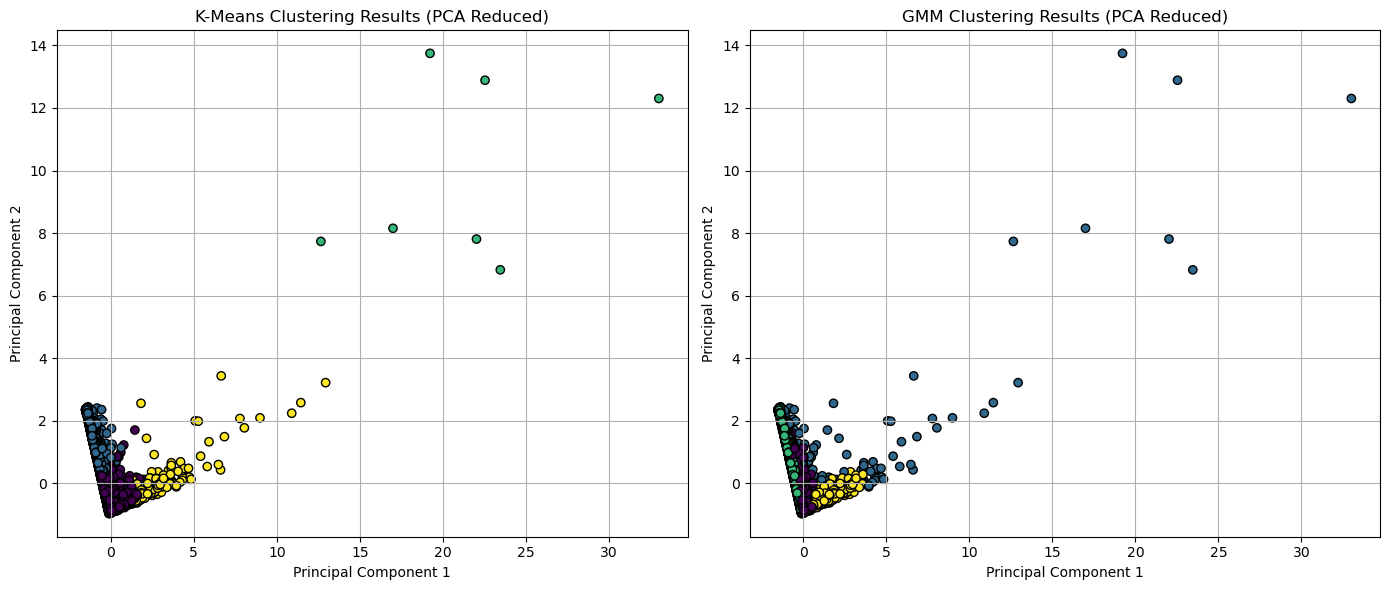

In [10]:
# Create a figure with one row and two columns:
fig, axes = plt.subplots(1, 2, figsize = (14, 6))

# Scatter plot of k-means clusters in the first two principal components:
axes[0].scatter(rfm_pca["PC1"], rfm_pca["PC2"], c = rfm["KMeans_Cluster"], 
                cmap = "viridis", marker = "o", edgecolor = "k", vmin = 0, 
                vmax = optimal_k - 1)
axes[0].set_xlabel("Principal Component 1")
axes[0].set_ylabel("Principal Component 2")
axes[0].set_title("K-Means Clustering Results (PCA Reduced)")
axes[0].grid(True)

# Scatter plot of GMM clusters in the first two principal components:
axes[1].scatter(rfm_pca["PC1"], rfm_pca["PC2"], c = rfm["GMM_Cluster"], 
            cmap = "viridis", marker = "o", edgecolor = "k", vmin = 0, 
            vmax = optimal_k - 1)
axes[1].set_xlabel("Principal Component 1")
axes[1].set_ylabel("Principal Component 2")
axes[1].set_title("GMM Clustering Results (PCA Reduced)")
axes[1].grid(True)

plt.tight_layout()
plt.show()